# Step 1: Load one Allen Brain Observatory two-photon session
Pick one Sst-IRES-Cre / VISp experiment, load dF/F traces, print basic info, plot 5 neurons for 60 s.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from allensdk.core.brain_observatory_cache import BrainObservatoryCache

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
boc = BrainObservatoryCache(manifest_file=str(ROOT / 'data/brain_observatory/manifest.json'))

## Pick one experiment
Sst-IRES-Cre line, VISp area. Take the lowest experiment id so the choice is reproducible.

In [2]:
exps = boc.get_ophys_experiments(cre_lines=['Sst-IRES-Cre'], targeted_structures=['VISp'])
print('Matching experiments:', len(exps))
exp = min(exps, key=lambda e: e['id'])
exp

Matching experiments: 212


{'id': 573720508,
 'imaging_depth': 275,
 'targeted_structure': 'VISp',
 'cre_line': 'Sst-IRES-Cre',
 'reporter_line': 'Ai148(TIT2L-GC6f-ICL-tTA2)',
 'acquisition_age_days': 89,
 'experiment_container_id': 573720506,
 'session_type': 'three_session_A',
 'donor_name': '297620',
 'specimen_name': 'Sst-IRES-Cre;Ai148(CAM)-297620',
 'fail_eye_tracking': False}

## Load dF/F traces
`dff` has shape (neurons, frames).

In [3]:
data_set = boc.get_ophys_experiment_data(exp['id'])
timestamps, dff = data_set.get_dff_traces()

n_neurons, n_frames = dff.shape
frame_rate = 1 / np.median(np.diff(timestamps))
duration_s = timestamps[-1] - timestamps[0]

print(f"Experiment id:  {exp['id']}")
print(f"Cre line:       {exp['cre_line']}")
print(f"Area:           {exp['targeted_structure']}")
print(f"Imaging depth:  {exp['imaging_depth']} um")
print(f"Session type:   {exp['session_type']}")
print(f"Neurons:        {n_neurons}")
print(f"Frames:         {n_frames}")
print(f"Frame rate:     {frame_rate:.2f} Hz")
print(f"Duration:       {duration_s:.1f} s ({duration_s/60:.1f} min)")

Experiment id:  573720508
Cre line:       Sst-IRES-Cre
Area:           VISp
Imaging depth:  275 um
Session type:   three_session_A
Neurons:        10
Frames:         115468
Frame rate:     30.08 Hz
Duration:       3839.3 s (64.0 min)


## Plot 5 random neurons over 60 s

Plotted neuron indices: [4, 7, 2, 3, 5]


Max dF/F in window: [3.06, 2.7, 1.3, 1.17, 0.85]


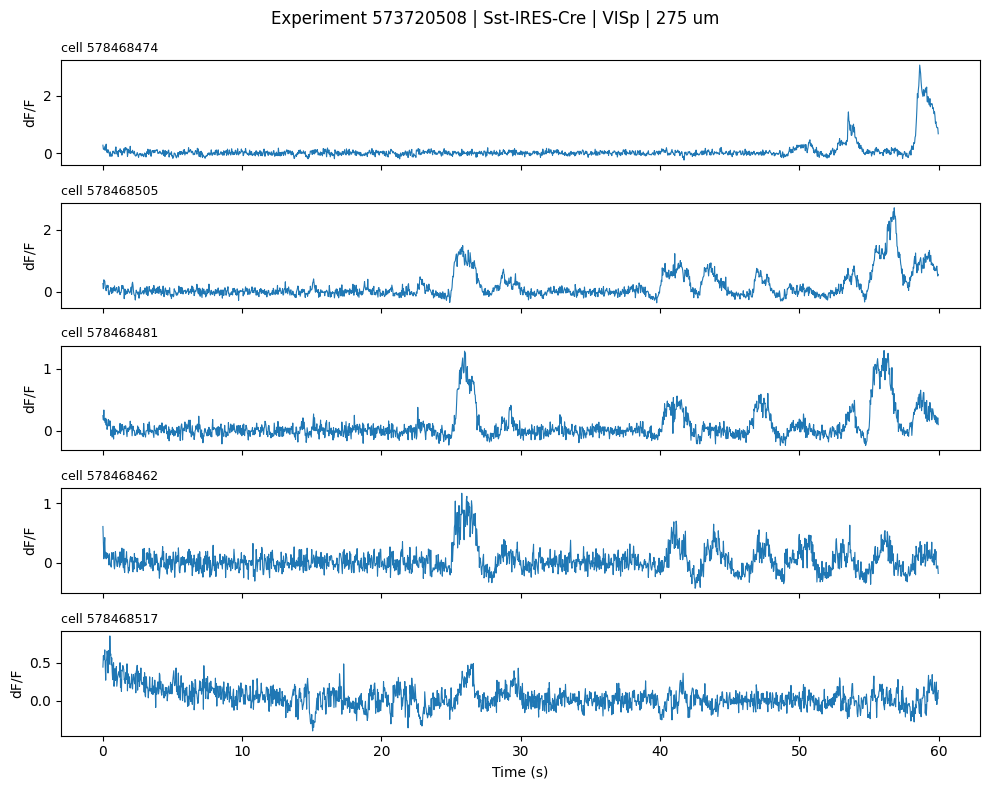

In [4]:
rng = np.random.default_rng(0)
picked = rng.choice(n_neurons, size=min(5, n_neurons), replace=False)
cell_ids = data_set.get_cell_specimen_ids()

t0 = timestamps[0]
win = (timestamps - t0) < 60

fig, axes = plt.subplots(len(picked), 1, figsize=(10, 8), sharex=True)
for ax, i in zip(axes, picked):
    ax.plot(timestamps[win] - t0, dff[i, win], lw=0.8)
    ax.set_ylabel('dF/F')
    ax.set_title(f'cell {cell_ids[i]}', fontsize=9, loc='left')
axes[-1].set_xlabel('Time (s)')
fig.suptitle(f"Experiment {exp['id']} | {exp['cre_line']} | {exp['targeted_structure']} | {exp['imaging_depth']} um")
fig.tight_layout()

(ROOT / 'plots').mkdir(exist_ok=True)
fig.savefig(ROOT / 'plots/step1_traces.png', dpi=150)
print('Plotted neuron indices:', picked.tolist())
print('Max dF/F in window:', [round(float(v), 2) for v in dff[picked][:, win].max(axis=1)])